# Projekt Technika Obrazowa - Wiktor Kęska - Klasyfikacja znaków drogowych

In [20]:
import os

import numpy as np
import cv2
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from skimage.feature import hog
from skimage import exposure
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.pipeline import make_pipeline

print(cv2.__version__)

5.0.0


In [21]:
DATA_PATH = "dane-wkeska"
classes = sorted([x for x in os.listdir(DATA_PATH) if os.path.isdir(os.path.join(DATA_PATH, x))])
dirs = [os.path.join(DATA_PATH, x) for x in classes]

## Rozkład obrazów według klas

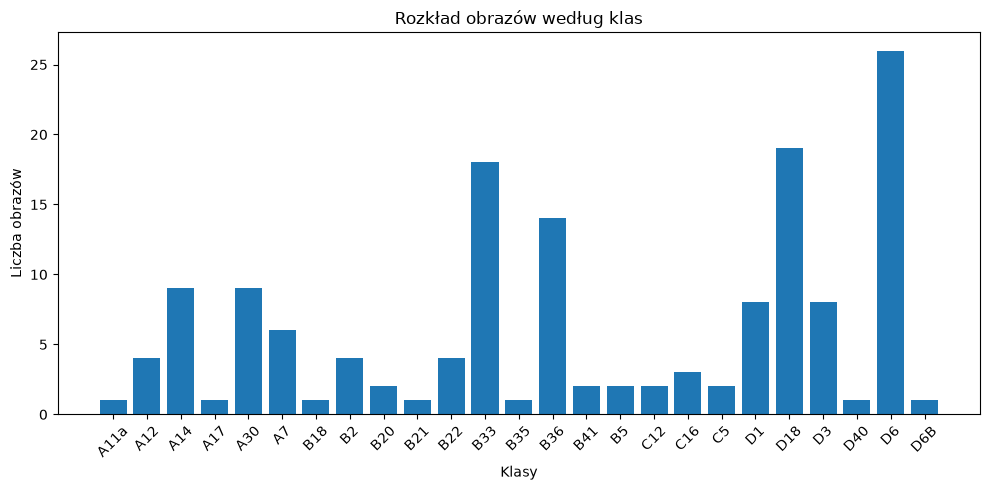

In [22]:
classes_count = [len(os.listdir(x)) for x in dirs]
plt.figure(figsize=(10, 5))
plt.bar(classes, classes_count)
plt.xlabel("Klasy")
plt.ylabel("Liczba obrazów")
plt.title("Rozkład obrazów według klas")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## Wyświetlenie przykładowych obrazów z każdej klasy

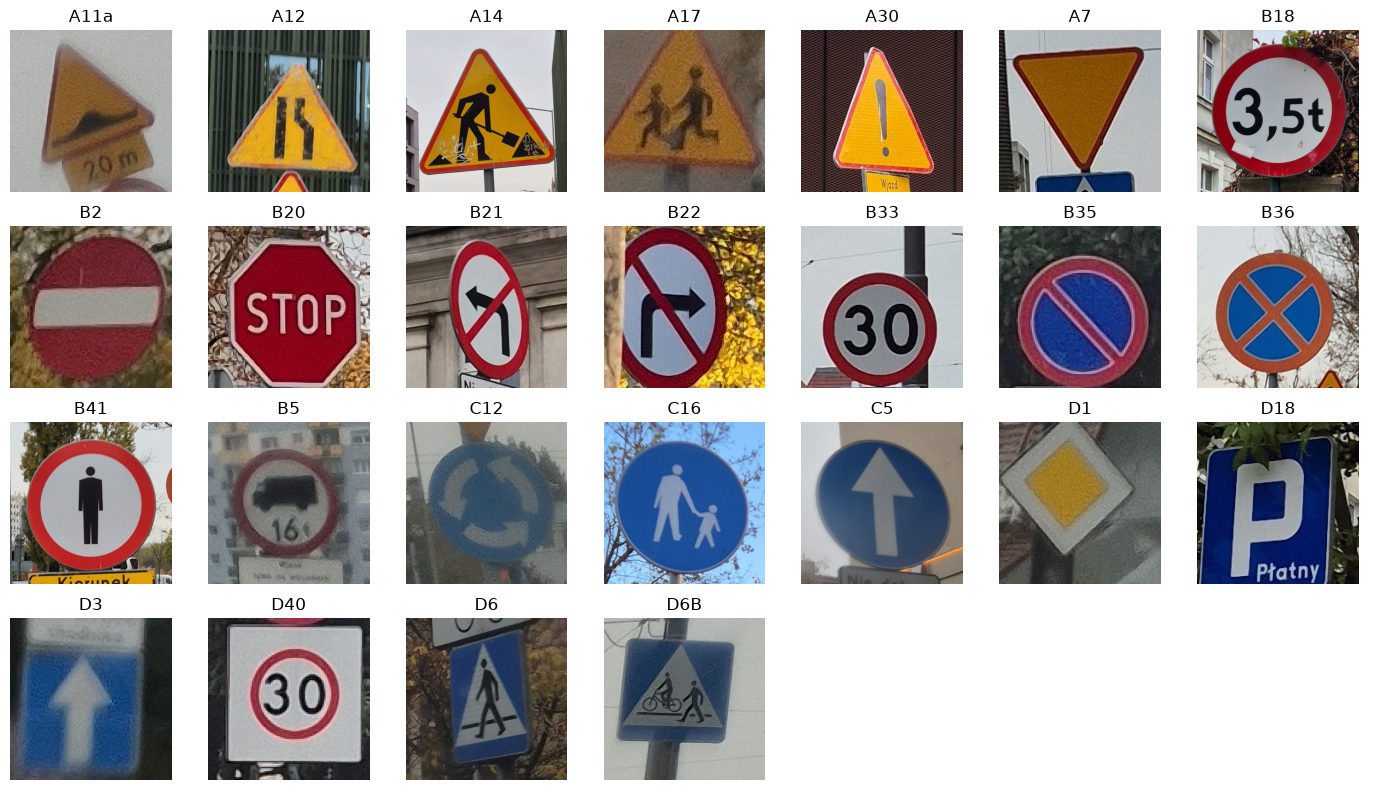

In [23]:
cols = 7
rows = int(np.ceil(len(dirs) / cols))
fig, axes = plt.subplots(rows, cols, figsize=(14, rows * 2))
for ax in axes.flatten()[len(dirs):]:
    ax.axis('off')
for ax, dir, class_name in zip(axes.flatten(), dirs, classes):
    img_path = os.path.join(dir, os.listdir(dir)[0])
    img = cv2.imread(img_path)
    ax.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
    ax.set_title(class_name)
    ax.axis('off')
plt.tight_layout()
plt.show()

## Wczytanie danych do NumPy
Zadanie A: 3 konkretne znaki (D6, D18, B33). Zadanie B: 3 grupy znaków (A – ostrzegawcze, B – zakazu, D – informacyjne). Obrazy skalowane do 64×64.

Task A: 63 images, Task B: 142 images


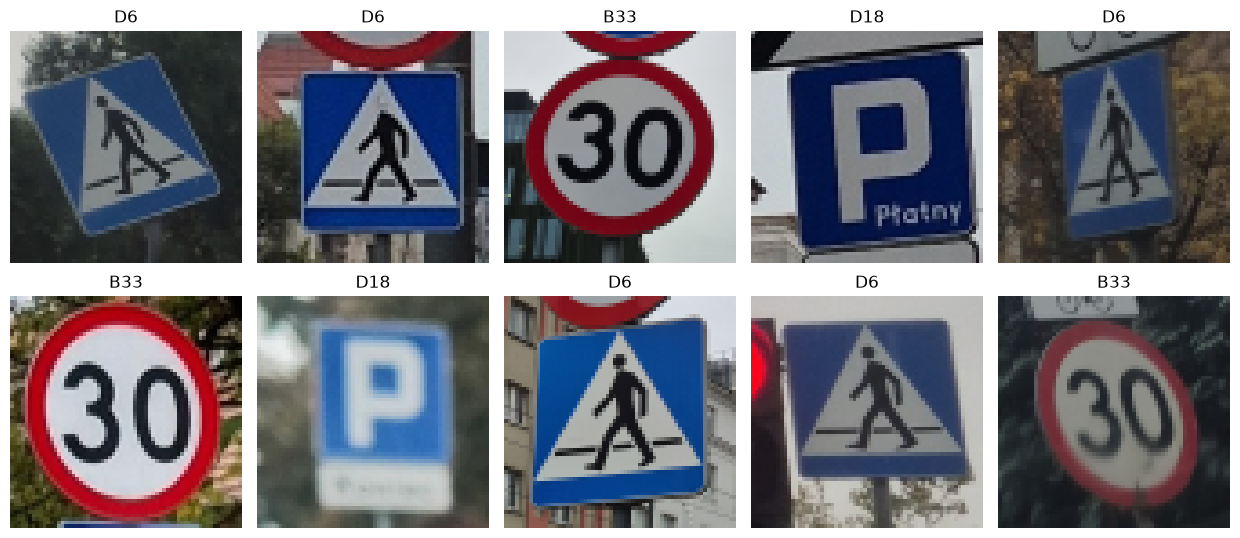

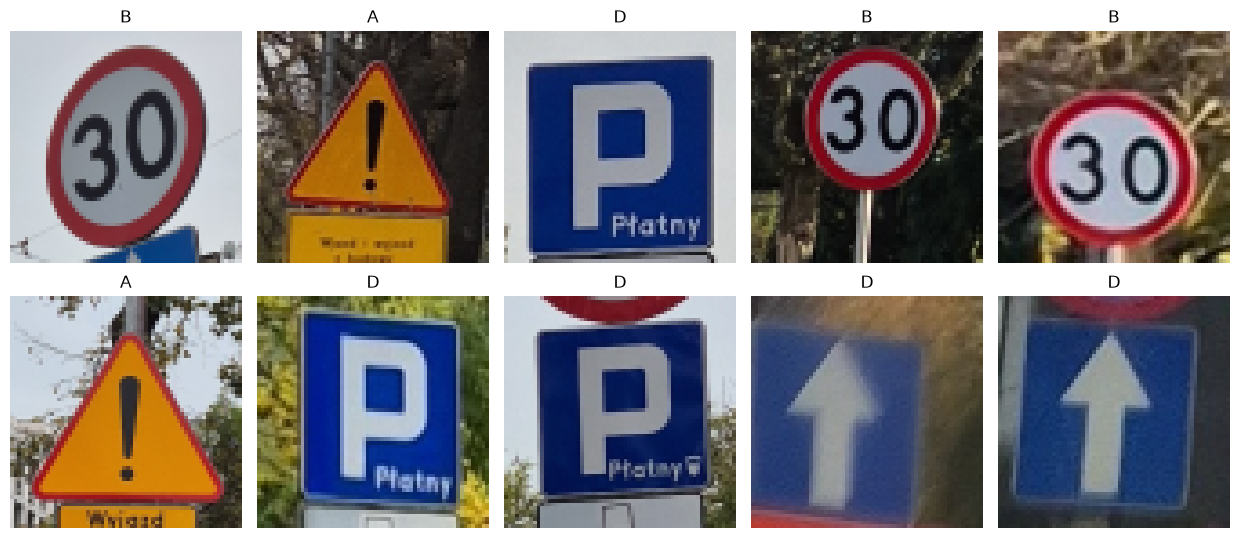

In [24]:
TASK_A = ["D6", "D18", "B33"]  # najliczniejsze klasy w dane-wkeska
TASK_B = ["A", "B", "D"]  # ostrzegawcze, zakazu, nakazu, informacyjne


def load_images(tasks, size=64, exact=False):
    images = []
    labels = []
    for task in tasks:
        dirs = [os.path.join(DATA_PATH, dir) for dir in os.listdir(DATA_PATH) if
                (dir.startswith(task) if not exact else task == dir)]
        for dir_path in dirs:
            for img_name in os.listdir(dir_path):
                img_path = os.path.join(dir_path, img_name)
                img = cv2.imread(img_path)
                img = cv2.resize(img, (size, size),
                                 interpolation=cv2.INTER_AREA)  # inter_area uśrednia pixele i nie tworzy postrzępnych artefaktów
                images.append(img)
                labels.append(task)
    return np.array(images), np.array(labels)


a_images, a_labels = load_images(TASK_A, exact=True)
b_images, b_labels = load_images(TASK_B)

print(f"Task A: {len(a_images)} images, Task B: {len(b_images)} images")


def show_random(images, labels, n=10, cols=5):
    idx = np.random.choice(len(images), n, replace=False)
    rows = int(np.ceil(n / cols))
    fig, axes = plt.subplots(rows, cols, figsize=(cols * 2.5, rows * 2.8))
    for ax, i in zip(axes.flatten(), idx):
        ax.imshow(cv2.cvtColor(images[i], cv2.COLOR_BGR2RGB))
        ax.set_title(labels[i])
        ax.axis('off')
    plt.tight_layout()
    plt.show()


show_random(a_images, a_labels)
show_random(b_images, b_labels)



## Podział na zbiór treningowy i testowy
Podział 80/20 ze stratyfikacją, żeby proporcje klas były takie same w obu zbiorach.

In [25]:
Xa_train, Xa_test, ya_train, ya_test = train_test_split(a_images, a_labels, test_size=0.2, random_state=42,
                                                        stratify=a_labels)
Xb_train, Xb_test, yb_train, yb_test = train_test_split(b_images, b_labels, test_size=0.2, random_state=42,
                                                        stratify=b_labels)

#shapes
print("Task A shapes:", Xa_train.shape, ya_train.shape, Xa_test.shape, ya_test.shape)
print("Task B shapes:", Xb_train.shape, yb_train.shape, Xb_test.shape, yb_test.shape)

Task A shapes: (50, 64, 64, 3) (50,) (13, 64, 64, 3) (13,)
Task B shapes: (113, 64, 64, 3) (113,) (29, 64, 64, 3) (29,)


## Segmentacja kolorów (HSV)
Maski koloru czerwonego, niebieskiego i żółtego wyznaczone przez `cv2.inRange` w przestrzeni HSV, oczyszczone otwarciem morfologicznym.

In [26]:
def color_masks(img):
    blur = cv2.GaussianBlur(img, (3, 3), 0)
    hsv = cv2.cvtColor(blur, cv2.COLOR_BGR2HSV)  # uzywamy hsv bo jest bardziej odporny na zmiany oswietlenia
    red = cv2.inRange(hsv, (0, 70, 50), (10, 255, 255)) | cv2.inRange(hsv, (170, 70, 50), (180, 255, 255))
    blue = cv2.inRange(hsv, (100, 100, 40), (130, 255, 255))
    yellow = cv2.inRange(hsv, (15, 80, 80), (35, 255, 255))
    kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (3, 3))
    return cv2.morphologyEx(red, cv2.MORPH_OPEN, kernel), cv2.morphologyEx(blue, cv2.MORPH_OPEN,
                                                                           kernel), cv2.morphologyEx(yellow,
                                                                                                     cv2.MORPH_OPEN,
                                                                                                     kernel)


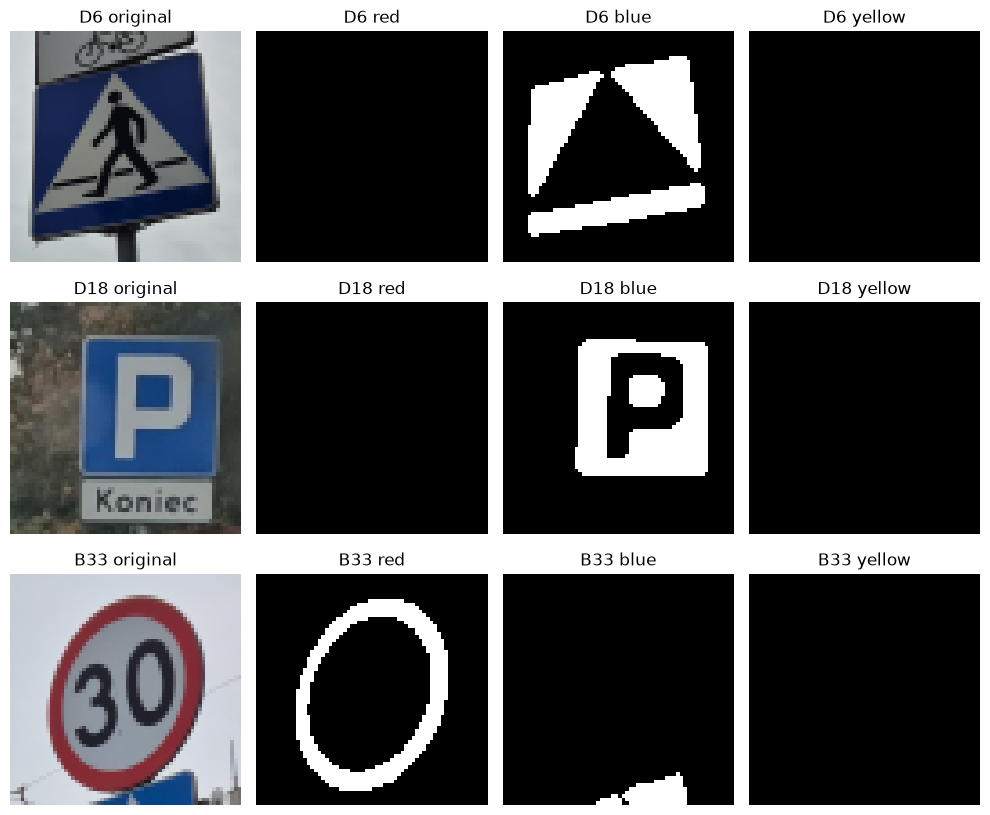

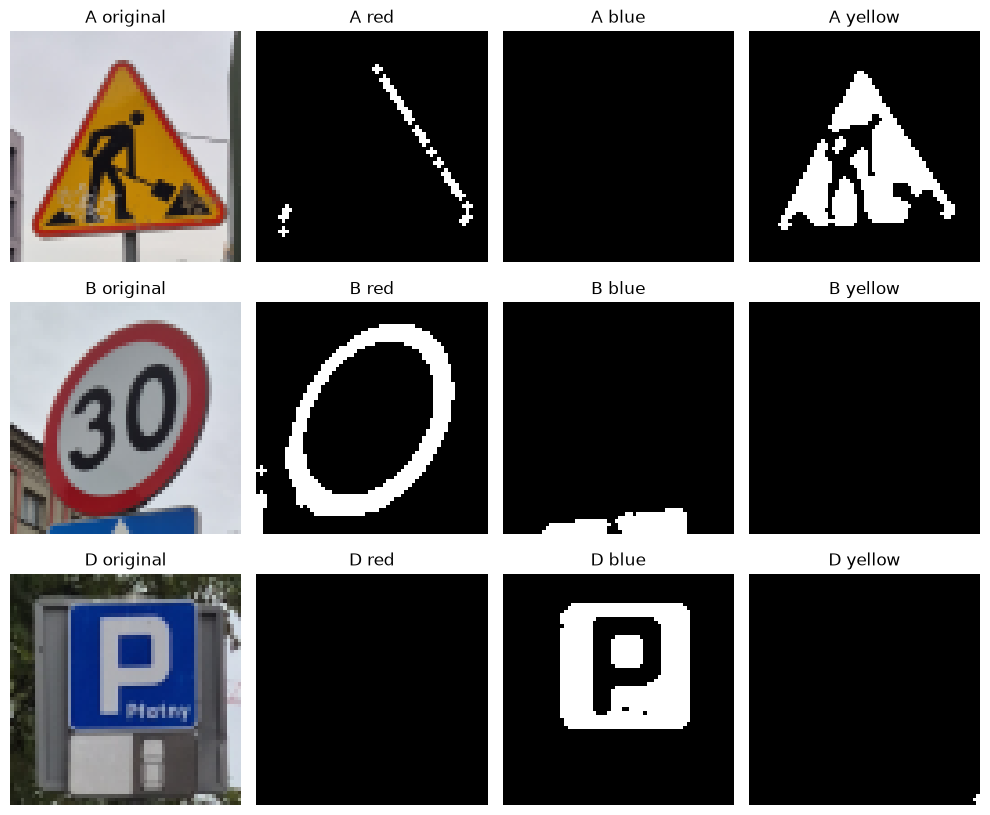

In [27]:
def show_masks_per_class(images, labels, classes):
    cols = 4
    rows = len(classes)
    fig, axes = plt.subplots(rows, cols, figsize=(cols * 2.5, rows * 2.8))
    for ax, cls in zip(axes, classes):
        i = np.random.choice(np.where(labels == cls)[0])  # losowy indeks z danej klasy
        red, blue, yellow = color_masks(images[i])

        ax[0].imshow(cv2.cvtColor(images[i], cv2.COLOR_BGR2RGB))
        ax[0].set_title(cls + " " + "original")

        ax[1].imshow(red, cmap='gray')
        ax[1].set_title(cls + " " + "red")

        ax[2].imshow(blue, cmap='gray')
        ax[2].set_title(cls + " " + "blue")

        ax[3].imshow(yellow, cmap='gray')
        ax[3].set_title(cls + " " + "yellow")

        for row in ax:
            row.axis('off')
    plt.tight_layout()
    plt.show()


show_masks_per_class(a_images, a_labels, TASK_A)
show_masks_per_class(b_images, b_labels, TASK_B)


In [28]:
for task in TASK_A:
    print(f"Task {task}: {np.sum(a_labels == task)} images")
    print(
        f"red %: {np.mean([np.sum(color_masks(img)[0]) for img, label in zip(a_images, a_labels) if label == task]) / (64 * 64 * 255) * 100:.2f}%")
    print(
        f"blue %: {np.mean([np.sum(color_masks(img)[1]) for img, label in zip(a_images, a_labels) if label == task]) / (64 * 64 * 255) * 100:.2f}%")
    print(
        f"yellow %: {np.mean([np.sum(color_masks(img)[2]) for img, label in zip(a_images, a_labels) if label == task]) / (64 * 64 * 255) * 100:.2f}%")
    print("")

Task D6: 26 images
red %: 2.89%
blue %: 23.87%
yellow %: 2.05%

Task D18: 19 images
red %: 0.84%
blue %: 30.95%
yellow %: 2.46%

Task B33: 18 images
red %: 20.01%
blue %: 1.53%
yellow %: 3.87%



## Wyznaczanie konturu znaku
Połączenie masek, domknięcie morfologiczne, wybór dużych konturów i otoczka wypukła (convex hull).

In [29]:
def get_contour(img):
    red, blue, yellow = color_masks(img)
    contour = red | blue | yellow
    kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (5, 5))
    sign = cv2.morphologyEx(contour, cv2.MORPH_CLOSE, kernel)
    contours, _ = cv2.findContours(sign, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    if len(contours) == 0:
        return None, sign
    max_area = max(cv2.contourArea(c) for c in contours)
    big = [c for c in contours if cv2.contourArea(c) >= 0.2 * max_area]
    return cv2.convexHull(np.vstack(big)), sign

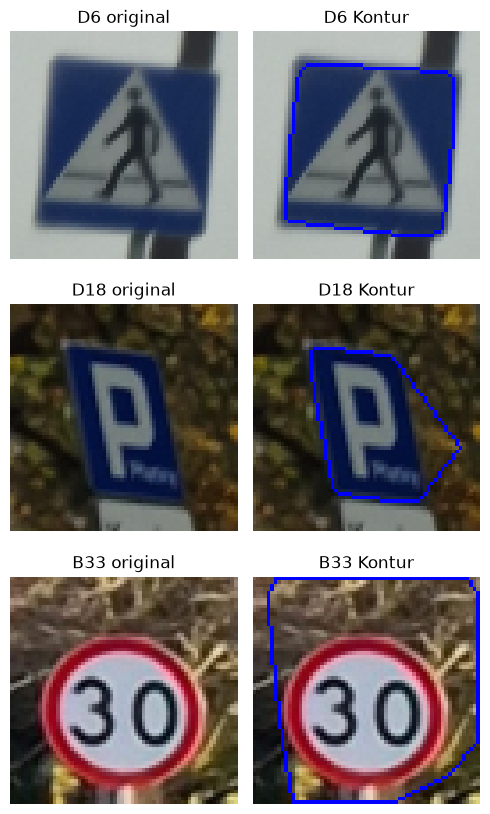

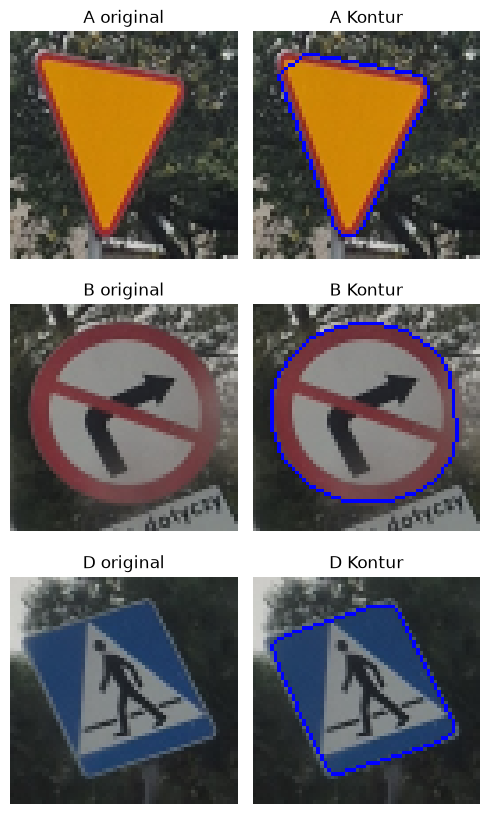

In [30]:
def show_contour_per_class(images, labels, classes):
    cols = 2
    rows = len(classes)
    fig, axes = plt.subplots(rows, cols, figsize=(cols * 2.5, rows * 2.8))
    for ax, cls in zip(axes, classes):
        i = np.random.choice(np.where(labels == cls)[0])  # losowy indeks z danej klasy
        contour, _ = get_contour(images[i])
        vis = images[i].copy()
        cv2.drawContours(vis, [contour], 0, 255, 1)

        ax[0].imshow(cv2.cvtColor(images[i], cv2.COLOR_BGR2RGB))
        ax[0].set_title(cls + " " + "original")

        ax[1].imshow(cv2.cvtColor(vis, cv2.COLOR_BGR2RGB))
        ax[1].set_title(cls + " " + "Kontur")

        for row in ax:
            row.axis('off')
    plt.tight_layout()
    plt.show()


show_contour_per_class(a_images, a_labels, TASK_A)
show_contour_per_class(b_images, b_labels, TASK_B)


## Cechy kształtu
Kolistość, extent, wypełnienie, liczba wierzchołków oraz 7 momentów Hu (w skali logarytmicznej).

In [31]:
def features(img):
    contour, sign = get_contour(img)
    if contour is None:
        return [0] * 11
    area = cv2.contourArea(contour)
    perimeter = cv2.arcLength(contour, True)

    #okraglosc
    circularity = 4 * np.pi * area / (perimeter ** 2)

    # prostokatnosc
    x, y, w, h = cv2.boundingRect(contour)
    extent = area / (w * h)

    # wyolenienie
    inside = np.zeros_like(sign)
    cv2.drawContours(inside, [contour], -1, 255, -1)
    fill = (sign[inside > 0] > 0).mean()

    # liczba wierzcholkow
    approx = cv2.approxPolyDP(contour, 0.04 * perimeter, True)
    vertices = len(approx)

    # momentu hu - ksztalt kontury bez wzgledu na obrocenie
    hu = cv2.HuMoments(cv2.moments(contour)).flatten()
    hu = -np.sign(hu) * np.log10(np.abs(hu) + 1e-10)

    return [circularity, extent, fill, vertices] + list(hu)

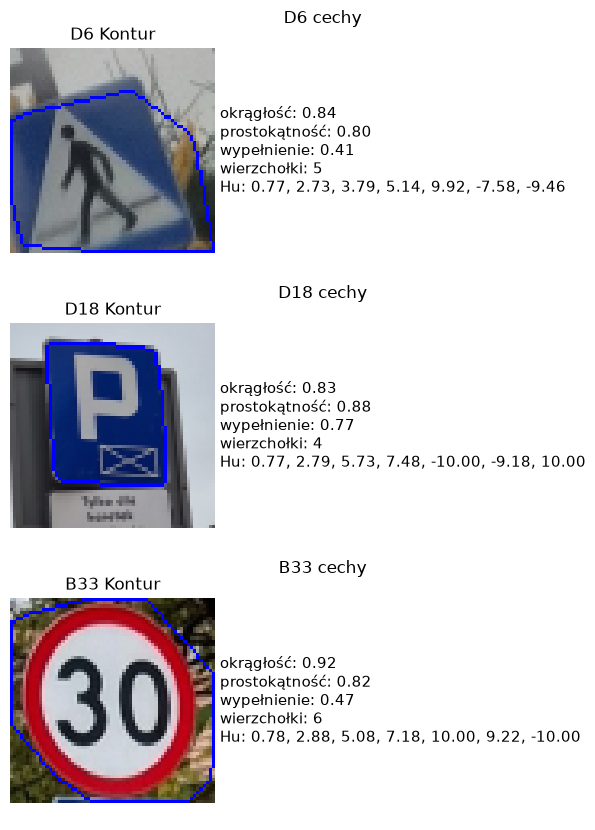

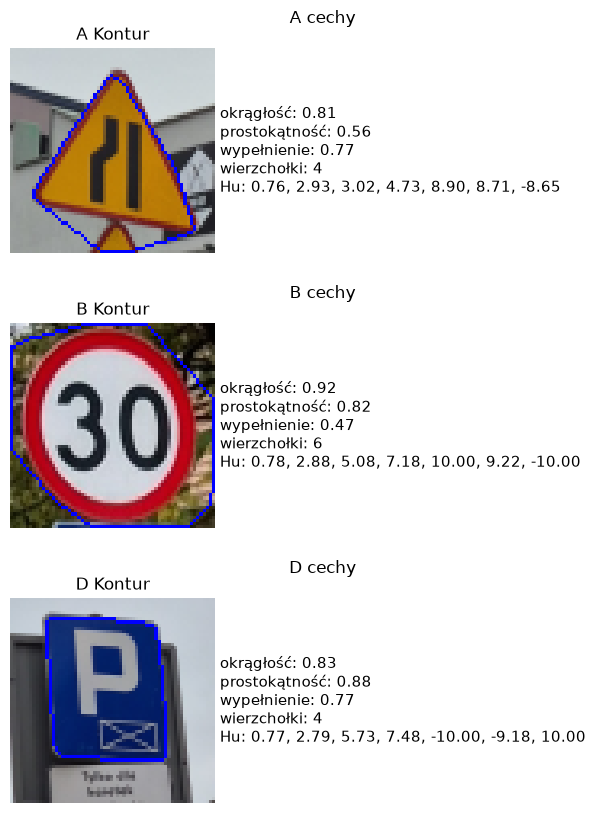

In [32]:
def show_features_per_class(images, labels, classes):
    cols = 2
    rows = len(classes)
    fig, axes = plt.subplots(rows, cols, figsize=(cols * 3, rows * 2.8))
    for ax, cls in zip(axes, classes):
        i = np.random.choice(np.where(labels == cls)[0])  # losowy indeks z danej klasy
        contour, _ = get_contour(images[i])
        vis = images[i].copy()
        cv2.drawContours(vis, [contour], 0, 255, 1)
        f = features(images[i])

        ax[0].imshow(cv2.cvtColor(vis, cv2.COLOR_BGR2RGB))
        ax[0].set_title(cls + " " + "Kontur")

        ax[1].text(0, 0.5,
                   f"okrągłość: {f[0]:.2f}\n"
                   f"prostokątność: {f[1]:.2f}\n"
                   f"wypełnienie: {f[2]:.2f}\n"
                   f"wierzchołki: {f[3]:.0f}\n"
                   "Hu: " + ", ".join(f"{h:.2f}" for h in f[4:11]),
                   fontsize=11, va='center')
        ax[1].set_title(cls + " " + "cechy")

        for row in ax:
            row.axis('off')
    plt.tight_layout()
    plt.show()


show_features_per_class(a_images, a_labels, TASK_A)
show_features_per_class(b_images, b_labels, TASK_B)


## Cechy HOG
Histogram zorientowanych gradientów – opisuje piktogram wewnątrz znaku.

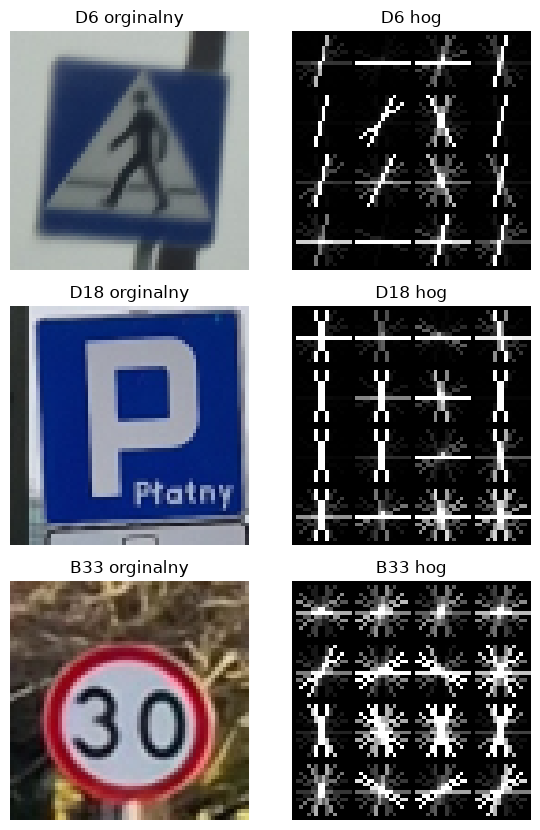

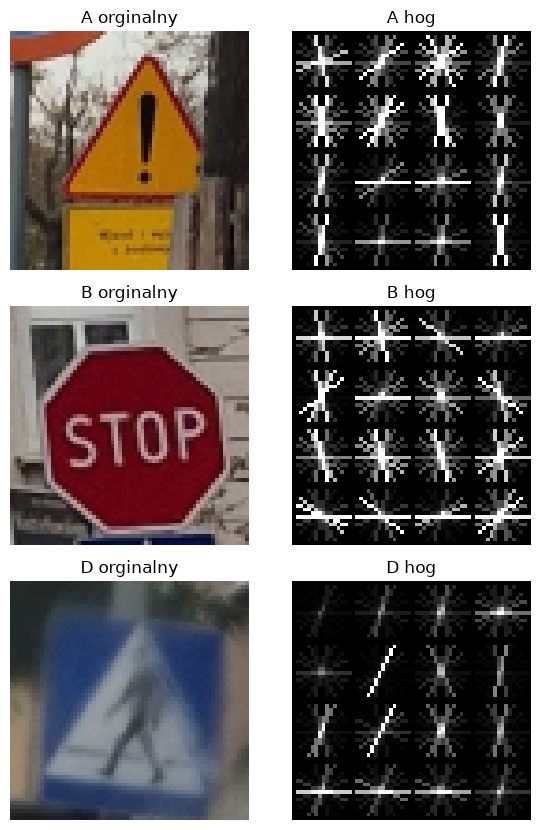

In [33]:
def hog_features(img, visualize=False):
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    return hog(gray, orientations=9, pixels_per_cell=(16, 16), cells_per_block=(2, 2), visualize=visualize)


def show_hog_per_class(images, labels, classes):
    cols = 2
    rows = len(classes)
    fig, axes = plt.subplots(rows, cols, figsize=(cols * 3, rows * 2.8))
    for ax, cls in zip(axes, classes):
        i = np.random.choice(np.where(labels == cls)[0])  # losowy indeks z danej klasy
        _, hog_img = hog_features(images[i], True)

        ax[0].imshow(cv2.cvtColor(images[i], cv2.COLOR_BGR2RGB))
        ax[0].set_title(cls + " " + "orginalny")

        ax[1].imshow(exposure.rescale_intensity(hog_img, in_range=(0, 10)), cmap='gray')
        ax[1].set_title(cls + " " + "hog")

        for row in ax:
            row.axis('off')
    plt.tight_layout()
    plt.show()


show_hog_per_class(a_images, a_labels, TASK_A)
show_hog_per_class(b_images, b_labels, TASK_B)

## Budowa wektorów cech
G – cechy geometryczne (udział kolorów + kształt, 14 cech), H – cechy HOG (324 cechy).

In [34]:
def geom_features(img):
    r, b, y = color_masks(img)
    f = features(img)
    return [r.mean() / 255, b.mean() / 255, y.mean() / 255] + f


Ga_train = np.array([geom_features(img) for img in Xa_train])
Ga_test = np.array([geom_features(img) for img in Xa_test])

Gb_train = np.array([geom_features(img) for img in Xb_train])
Gb_test = np.array([geom_features(img) for img in Xb_test])

print(f"Ga_train shape: {Ga_train.shape}")
print(f"Gb_train shape: {Gb_train.shape}")



Ga_train shape: (50, 14)
Gb_train shape: (113, 14)


In [35]:
Ha_train = np.array([hog_features(img) for img in Xa_train])
Ha_test = np.array([hog_features(img) for img in Xa_test])

Hb_train = np.array([hog_features(img) for img in Xb_train])
Hb_test = np.array([hog_features(img) for img in Xb_test])

print(f"Ha_train shape: {Ha_train.shape}")
print(f"Hb_train shape: {Hb_train.shape}")


Ha_train shape: (50, 324)
Hb_train shape: (113, 324)


## Klasyfikacja i ocena na zbiorze testowym
k-NN (k=3) i SVM (jądro RBF), każdy ze standaryzacją cech (`StandardScaler`).

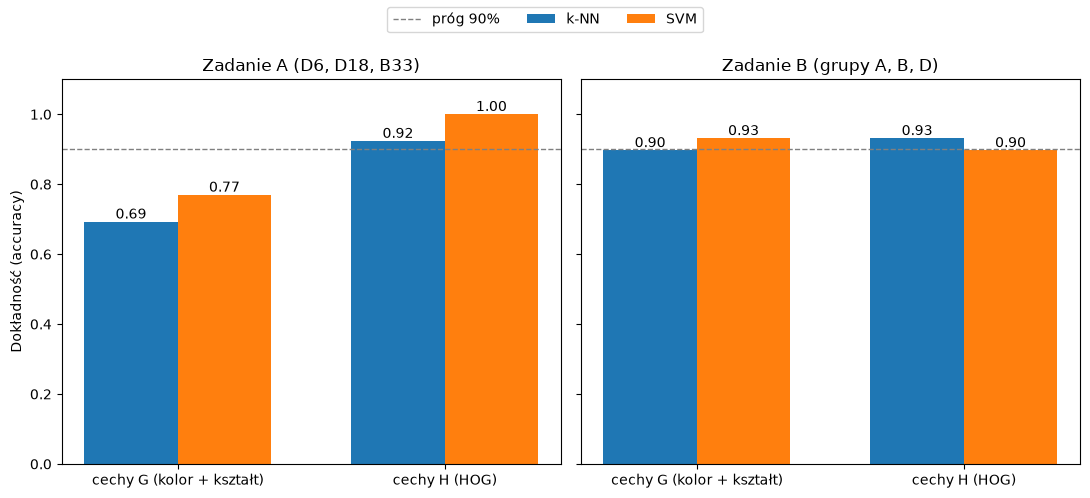

In [36]:
def evaluate(F_train, y_train, F_test, y_test, classifier):
    model = make_pipeline(StandardScaler(), classifier)
    model.fit(F_train, y_train)
    return model.score(F_test, y_test)


tasks = {
    "Zadanie A (D6, D18, B33)": {
        "G": (Ga_train, ya_train, Ga_test, ya_test),
        "H": (Ha_train, ya_train, Ha_test, ya_test),
    },
    "Zadanie B (grupy A, B, D)": {
        "G": (Gb_train, yb_train, Gb_test, yb_test),
        "H": (Hb_train, yb_train, Hb_test, yb_test),
    },
}
classifiers = {
    "k-NN": lambda: KNeighborsClassifier(n_neighbors=3),
    "SVM": lambda: SVC(kernel="rbf"),
}

width = 0.35
fig, axes = plt.subplots(1, len(tasks), figsize=(11, 5), sharey=True)
for ax, (task, datasets) in zip(axes, tasks.items()):
    x = np.arange(len(datasets))
    for i, (clf, make) in enumerate(classifiers.items()):
        scores = [evaluate(*data, make()) for data in datasets.values()]
        bars = ax.bar(x + (i - 0.5) * width, scores, width, label=clf)
        ax.bar_label(bars, fmt="%.2f")
    ax.axhline(0.9, color="gray", linestyle="--", linewidth=1, label="próg 90%")
    ax.set_xticks(x, ["cechy G (kolor + kształt)", "cechy H (HOG)"])
    ax.set_ylim(0, 1.1)
    ax.set_title(task)
axes[0].set_ylabel("Dokładność (accuracy)")
fig.legend(*axes[0].get_legend_handles_labels(), loc="upper center", ncol=3)
plt.tight_layout(rect=(0, 0, 1, 0.92))
plt.show()

## Walidacja krzyżowa
5-krotna stratyfikowana walidacja krzyżowa – bardziej wiarygodna ocena niż pojedynczy, mały zbiór testowy.

In [37]:
from sklearn.model_selection import cross_val_score, StratifiedKFold

# walidacja krzyzowa 5-fold na zbiorze treningowym
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
for task, datasets in tasks.items():
    print(task)
    for feat, (F_train, y_train, F_test, y_test) in datasets.items():
        for clf, make in classifiers.items():
            model = make_pipeline(StandardScaler(), make())
            scores = cross_val_score(model, F_train, y_train, cv=skf)
            print(f"  {feat} {clf}: {scores.mean():.3f} +- {scores.std():.3f}  {np.round(scores, 2)}")
    print("")


Zadanie A (D6, D18, B33)
  G k-NN: 0.760 +- 0.185  [0.9 0.5 0.6 1.  0.8]
  G SVM: 0.820 +- 0.098  [0.8 0.7 0.8 1.  0.8]
  H k-NN: 1.000 +- 0.000  [1. 1. 1. 1. 1.]
  H SVM: 0.940 +- 0.049  [0.9 1.  0.9 1.  0.9]

Zadanie B (grupy A, B, D)
  G k-NN: 0.885 +- 0.019  [0.87 0.87 0.87 0.91 0.91]
  G SVM: 0.921 +- 0.017  [0.91 0.91 0.91 0.91 0.95]
  H k-NN: 0.886 +- 0.070  [0.83 0.78 0.96 0.91 0.95]
  H SVM: 0.859 +- 0.063  [0.87 0.74 0.91 0.86 0.91]



## Macierz pomyłek
Pokazuje, które klasy są ze sobą mylone.

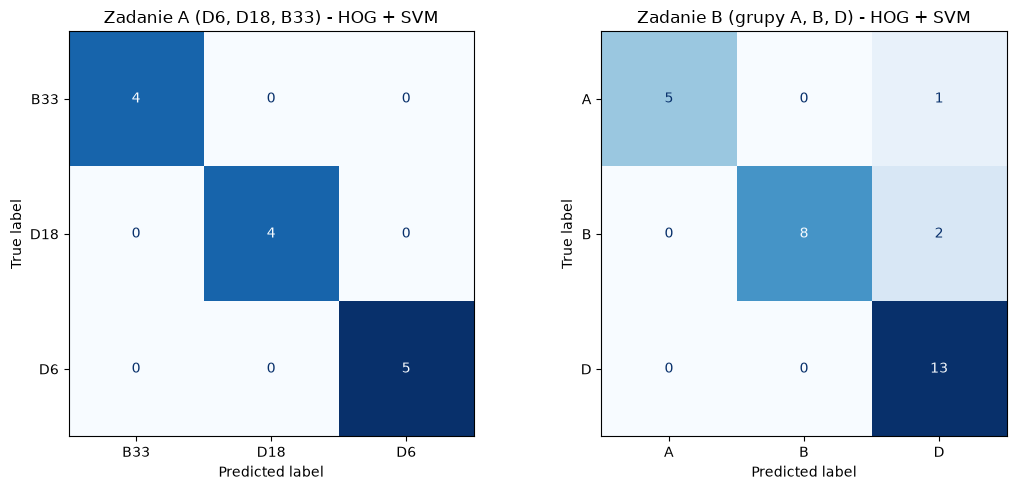

In [38]:
from sklearn.metrics import ConfusionMatrixDisplay

# macierz pomylek dla HOG + SVM na zbiorze testowym
fig, axes = plt.subplots(1, len(tasks), figsize=(11, 5))
for ax, (task, datasets) in zip(axes, tasks.items()):
    F_train, y_train, F_test, y_test = datasets["H"]
    model = make_pipeline(StandardScaler(), SVC(kernel="rbf"))
    model.fit(F_train, y_train)
    ConfusionMatrixDisplay.from_predictions(y_test, model.predict(F_test), ax=ax, cmap="Blues", colorbar=False)
    ax.set_title(task + " - HOG + SVM")
plt.tight_layout()
plt.show()
